### Performing LOO-PIT on Field-Level MCMCs with Fixed Initial Conditions

This code book performs LOO-PIT analysis on an MCMC chain provided by Hugo Simon and Arnaud Di Mattia (University of Paris-Saclay). 
The chains are Field-Level inference chains of galaxy density counts over a 32 x 32 x 32 voxel space.
These chains specifically have their initial conditions fixed and only samples over the cosmological parameters. 

First we load the necessary packages

In [1]:
Pkg.instantiate()
Pkg.resolve()

  No Changes to `~/.julia/v1.11/Project.toml`
  No Changes to `~/.julia/v1.11/Manifest.toml`


In [2]:
# Pkg.add("Turing")
# Pkg.add("Capse")
# Pkg.add("NPZ")
# Pkg.add(url="https://github.com/JuliaCosmologicalLikelihoods/PlanckLite.jl")
# Pkg.add("BenchmarkTools")
# Pkg.add("Plots")
# Pkg.add("Optim")
# Pkg.add("ForwardDiff")
# Pkg.add("LinearAlgebra")
# Pkg.add("Pathfinder")
# Pkg.add("MicroCanonicalHMC")
# Pkg.add("Transducers")
# Pkg.add("StatsPlots")
# Pkg.add("PairPlots")
# Pkg.add("LaTeXStrings")
# Pkg.add("MCMCChains")
# Pkg.add("PSIS")
# Pkg.add("ArviZ")
# Pkg.add("ArviZPythonPlots")
# Pkg.add("IrrationalConstants")
# Pkg.add("DimensionalData")
# Pkg.add("Statistics")

In [3]:
# using Turing
# using Capse
using NPZ
# # using PlanckLite
# using BenchmarkTools
# using Plots
# using Optim
# using ForwardDiff
# using Pathfinder
# #using MicroCanonicalHMC
# #using Transducers
# using StatsPlots
# #using PairPlots
# #using LaTeXStrings
# #using CairoMakie
# using MCMCChains
using PSIS
# include("utils.jl");
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants
using DimensionalData
using Statistics
using Plots

### PSIS

We begin by running Pareto Smoothed Importance Sampling (PSIS) on the full voxels, and storing the results.

The chains provided are a single file, which is loaded below. 

In [4]:
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/32_mesh_ic/logdf_mesh.npz")

Dict{String, Array{Float64, 5}} with 2 entries:
  "logcdf_mesh" => [-0.156297 -2.0561 … -2.42745 -1.10211; -2.17872 -0.759847 ……
  "logpdf_mesh" => [-4.14384 -4.228 … -4.49593 -3.67675; -4.31436 -3.58588 … -4…

For the process of PSIS, we need the logpdf_mesh field, which are the log probabilities of each voxel that the chain has determined by fitting the model to the full data set. That is, the logpdf_mesh represent $p(y | \theta)$

In [5]:
f["logpdf_mesh"]

4×512×32×32×32 Array{Float64, 5}:
[:, :, 1, 1, 1] =
 -4.14384  -4.228    -3.69503  -4.63193  …  -4.58571  -4.49593  -3.67675
 -4.31436  -3.58588  -6.32375  -3.58766     -3.96756  -4.92422  -5.8497
 -3.96405  -3.61775  -3.83658  -3.68633     -3.60402  -3.58632  -3.68495
 -5.13528  -3.58899  -3.75308  -3.59047     -3.58351  -4.71606  -3.58361

[:, :, 2, 1, 1] =
 -3.58839  -3.61592  -3.62798  -3.85122  …  -4.10314  -4.00285  -3.60924
 -3.58606  -3.5863   -3.60506  -4.24338     -3.75858  -4.10691  -4.52977
 -3.97432  -3.63563  -3.96442  -3.81189     -4.12873  -6.7649   -3.90184
 -4.04853  -3.60959  -4.18256  -4.18704     -4.20053  -3.60893  -4.07659

[:, :, 3, 1, 1] =
 -4.80183  -3.58908  -5.05352  -4.57403  …  -4.32736  -3.58261  -3.6555
 -3.66723  -6.09505  -3.77031  -3.96414     -4.00923  -3.59223  -3.60208
 -4.62465  -3.818    -4.0625   -3.89522     -3.71644  -3.63154  -4.24577
 -3.58265  -4.24938  -3.85895  -3.76115     -3.59167  -3.79775  -3.70067

;;; … 

[:, :, 30, 1, 1] =
 -3.6432

Each of the 32 x 32 x 32 voxels has 4 x 512 delta logdensities from the chain corresponding to that voxel.

Below, we create an array of vectors called logpdf_mesh to store the data from the file. Each of the 32 x 32 x 32 elements has a vector corresponding to a single voxel, and the vector holds the log probability values.

In [6]:
logpdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logpdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logpdf_mesh[i,j,k], vec(f["logpdf_mesh"][:,:,i,j,k]))
end

Thus, log_pdf is a data object representing the 32 x 32 x 32 voxels, with each element holding 2048 log probability values collected from the file.

In [7]:
logpdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-4.14384, -4.31436, -3.96405, -5.13528, -4.228, -3.58588, -3.61775, -3.58899, -3.69503, -6.32375  …  -3.60402, -3.58351, -4.49593, -4.92422, -3.58632, -4.71606, -3.67675, -5.8497, -3.68495, -3.58361]    …  [-3.60453, -3.58415, -3.59564, -4.41143, -4.49186, -4.53713, -3.97479, -3.79704, -3.77197, -4.04173  …  -3.8191, -4.29733, -3.62027, -4.50898, -3.63398, -3.68626, -3.65391, -3.9814, -3.68611, -3.58722]
 [-3.58839, -3.58606, -3.97432, -4.04853, -3.61592, -3.5863, -3.63563, -3.60959, -3.62798, -3.60506  …  -4.12873, -4.20053, -4.00285, -4.10691, -6.7649, -3.60893, -3.60924, -4.52977, -3.90184, -4.07659]      [-3.58613, -3.71885, -3.97411, -3.59547, -3.59709, -3.71342, -3.66684, -4.12942, -6.55909, -3.77619  …  -3.61253, -4.27588, -3.83761, -3.66848, -3.67651, -4.77702, -4.13488, -3.58914, -3.85567, -3.82058]
 [-4.80183, -3.66723, -4.62465, -3.58265, -3.58908, -6.09505, -3.818, -4.24938, -5.05352, -3.77031  …  -3.71644, -3.59167, -3.5826

In [8]:
logpdf_mesh[3,16,4]

2048-element Vector{Float64}:
 -3.6077709460373315
 -4.125597075842454
 -3.777443640860973
 -3.745949677595732
 -3.582612941073449
 -4.363105603721312
 -3.693156795019597
 -3.586872335157595
 -3.609337349608373
 -4.249775240787105
  ⋮
 -3.7066547522540536
 -4.00791431194799
 -5.643128393133329
 -5.655413130587514
 -4.1926854992035
 -4.087908033075091
 -3.5905006301193447
 -3.851465422428625
 -3.9680950507366286

Next, we perform Pareto Smoothed Importance Sampling (PSIS) on each voxel's vector of log pdf probabilities.

In [9]:
psis_result = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
for i in 1:32, j in 1:32, k in 1:32
    psis_result[i, j, k] = psis(-logpdf_mesh[i,j,k])
end

┌ Warning: Pareto shape k = 1.2 > 1. Corresponding importance sampling estimates are likely to be unstable and are unlikely to converge with additional samples.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:363
┌ Warning: Pareto shape k = 1.2 > 1. Corresponding importance sampling estimates are likely to be unstable and are unlikely to converge with additional samples.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:363
┌ Warning: Pareto shape k = 0.89 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warning: Pareto shape k = 0.89 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warning: Pareto shape k = 0.98 > 0.7. Resulting importance sampling estimates are likely to be unstable.
└ @ PSIS /Users/ethansmith/.julia/packages/PSIS/jp3Nb/src/core.jl:365
┌ Warni

The importance weights and the pareto shape values are stored in their own 32 x 32 x 32 arrays so that the PSIS weights and the pareto shape value can be recalled easily for each voxel if needed.

In [10]:
psis_weights = Array{Vector{Float64}}(undef, 32, 32, 32)
for i in 1:32, j in 1:32, k in 1:32
    psis_weights[i,j,k] = psis_result[i,j,k].weights
end

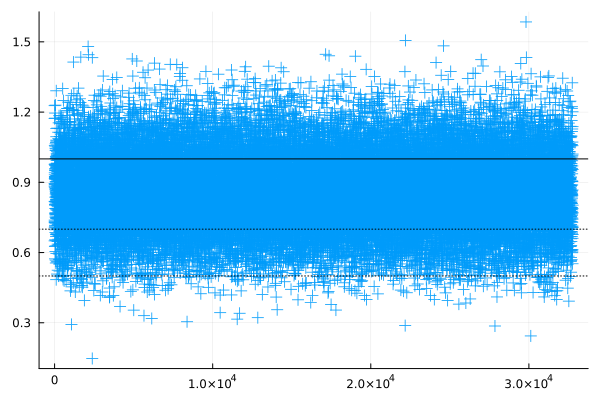

In [11]:
pareto_shapes = []
for i in 1:32, j in 1:32, k in 1:32
    append!(pareto_shapes, psis_result[i,j,k].pareto_shape)
end

psis_plot = Plots.scatter(pareto_shapes; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

The plot above is of the Pareto shape parameters from PSIS. Because the shape parameters are all under the threshhold of 0.5, this informs that the importance sampling is well-behaved and reliable for probability reweighting in the Leave One Out approach.

Now that we know the weights are reliable, we can proceed with the LOO-PIT analysis. The PSIS weights inform how to reweight $p(y | \theta)$ determined by the MCMC logpdf_mesh field, into $p(y_{-i} | \theta)$, the LOO probability density. 

First load the logcdf_mesh field from the MCMC chain file. Similar to logpdf_mesh, this field has contains 4 x 512 samples corresponding to the CDF of that particular voxel. It is stored below in an array with each voxel having an array of all CDF samples

In [13]:
logcdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logcdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logcdf_mesh[i,j,k], vec(f["logcdf_mesh"][:,:,i,j,k]))
end

In [14]:
logcdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-0.156297, -2.17872, -0.212218, -0.0397991, -2.0561, -0.759847, -0.503274, -0.607003, -1.1467, -0.00965143  …  -0.541314, -0.727655, -2.42745, -0.0520357, -0.764339, -2.71687, -1.10211, -4.09763, -1.12244, -0.658098]         …  [-0.53969, -0.649792, -0.572445, -2.31304, -0.092933, -0.0872305, -0.208137, -0.296077, -0.313536, -1.77805  …  -0.282106, -2.1548, -0.497367, -2.44493, -0.982745, -1.12566, -0.435184, -1.6825, -1.12528, -0.772753]
 [-0.610985, -0.628996, -0.208312, -1.78862, -0.507745, -0.626859, -0.465758, -0.896137, -0.963346, -0.876858  …  -1.91064, -2.01639, -1.71687, -1.87788, -5.14628, -0.526362, -0.894682, -2.47269, -0.238423, -1.83184]              [-0.628384, -1.2012, -0.208392, -0.829462, -0.838364, -1.18908, -0.416641, -1.91166, -4.91356, -0.310469  …  -0.516458, -0.127258, -0.271243, -0.414422, -0.404021, -0.0630492, -0.158568, -0.788565, -0.2613, -1.40595]
 [-0.0610213, -0.416101, -0.0773352, -0.685809, -0.788108, -

The CDF values are then able to be systemically reweighted by the PSIS weights in order to obtain the LOO-PIT final values.

In [15]:
loo_pit = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            loo_pit[i,j,k] = dot(psis_weights[i,j,k], exp.(logcdf_mesh[i,j,k]))
        end
    end
end

Plotting the LOO-PIT values in a histogram, we see the approximately uniform distribution of values as expected from a MCMC sampling based on a strong model.

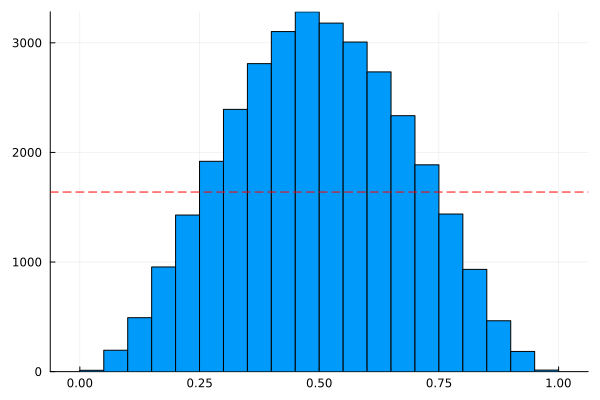

In [16]:
Plots.histogram(vec(loo_pit), legend=false, bins=20)
hline!([length(loo_pit) / 20], color=:red, linestyle=:dash)